# RNN, GRU and LSTM: Character-Level Language Models (PyTorch)

Following [D2L Ch. 9 Recurrent Neural Networks](https://d2l.ai/chapter_recurrent-neural-networks/index.html) and [Ch. 10 Modern RNNs](https://d2l.ai/chapter_recurrent-modern/index.html).

A **language model** predicts the next token from the ones before it. We train character-level models on H. G. Wells' *The Time Machine* and let them write text.

**Contents**
1. Text preprocessing: tokens, vocabulary, minibatches
2. A vanilla RNN from scratch (with gradient clipping)
3. An LSTM from scratch
4. Concise RNN / GRU / LSTM with `torch.nn` and a comparison

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lee2716/Dive_into_Deep_Learning_Code_Implementation/blob/main/rnn_lstm_gru.ipynb)

In [1]:
import math
import os
import re
import time
import urllib.request
from collections import Counter

import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cpu


## 1. Text Preprocessing

Keep only letters and spaces, lowercase everything, and treat each **character** as a token. The vocabulary is tiny (26 letters + space + `<unk>`), so the model can focus on learning sequence structure.

In [2]:
URL = 'http://d2l-data.s3-accelerate.amazonaws.com/timemachine.txt'
os.makedirs('data', exist_ok=True)
path = os.path.join('data', 'timemachine.txt')
if not os.path.exists(path):
    urllib.request.urlretrieve(URL, path)

with open(path) as f:
    raw_text = f.read()
text = re.sub('[^A-Za-z]+', ' ', raw_text).lower()
print(f'{len(text):,} characters')
print(text[:200])

173,428 characters
the time machine by h g wells i the time traveller for so it will be convenient to speak of him was expounding a recondite matter to us his grey eyes shone and twinkled and his usually pale face was f


In [3]:
class Vocab:
    """Map tokens to integer indices and back."""
    def __init__(self, tokens):
        counter = Counter(tokens)
        self.idx_to_token = ['<unk>'] + sorted(counter, key=lambda t: -counter[t])
        self.token_to_idx = {t: i for i, t in enumerate(self.idx_to_token)}

    def __len__(self):
        return len(self.idx_to_token)

    def __getitem__(self, tokens):
        return [self.token_to_idx.get(t, 0) for t in tokens]

    def to_tokens(self, indices):
        return [self.idx_to_token[int(i)] for i in indices]


vocab = Vocab(text)
corpus = torch.tensor(vocab[text])
print(len(vocab), 'tokens:', vocab.idx_to_token)

28 tokens: ['<unk>', ' ', 'e', 't', 'a', 'i', 'n', 'o', 's', 'h', 'r', 'd', 'l', 'm', 'u', 'c', 'f', 'w', 'g', 'y', 'p', 'b', 'v', 'k', 'x', 'z', 'j', 'q']


### Minibatches of subsequences

Each example is a window of `num_steps` characters; the label is the same window shifted by one. Every epoch we start at a random offset and shuffle the windows, so the model sees different splits.

In [4]:
def seq_data_iter(corpus, batch_size, num_steps):
    offset = torch.randint(0, num_steps, (1,)).item()
    num_subseqs = (len(corpus) - offset - 1) // num_steps
    starts = torch.randperm(num_subseqs) * num_steps + offset
    for i in range(0, num_subseqs - batch_size + 1, batch_size):
        idx = starts[i: i + batch_size]
        X = torch.stack([corpus[j: j + num_steps] for j in idx])
        Y = torch.stack([corpus[j + 1: j + 1 + num_steps] for j in idx])
        yield X, Y


X, Y = next(seq_data_iter(corpus, batch_size=2, num_steps=10))
print('X:', [''.join(vocab.to_tokens(x)) for x in X])
print('Y:', [''.join(vocab.to_tokens(y)) for y in Y])

X: ['ns as prac', ' him the l']
Y: ['s as pract', 'him the la']


## 2. A Vanilla RNN from Scratch

The hidden state carries information along the sequence:

$$\mathbf{H}_t = \tanh(\mathbf{X}_t \mathbf{W}_{xh} + \mathbf{H}_{t-1} \mathbf{W}_{hh} + \mathbf{b}_h), \qquad \mathbf{O}_t = \mathbf{H}_t \mathbf{W}_{hq} + \mathbf{b}_q$$

Inputs are one-hot vectors of length `len(vocab)`. The same weights are used at every time step.

In [5]:
class RNNScratch(nn.Module):
    def __init__(self, vocab_size, num_hiddens, sigma=0.01):
        super().__init__()
        self.vocab_size, self.num_hiddens = vocab_size, num_hiddens
        self.W_xh = nn.Parameter(torch.randn(vocab_size, num_hiddens) * sigma)
        self.W_hh = nn.Parameter(torch.randn(num_hiddens, num_hiddens) * sigma)
        self.b_h = nn.Parameter(torch.zeros(num_hiddens))
        self.W_hq = nn.Parameter(torch.randn(num_hiddens, vocab_size) * sigma)
        self.b_q = nn.Parameter(torch.zeros(vocab_size))

    def begin_state(self, batch_size):
        return torch.zeros(batch_size, self.num_hiddens, device=self.W_xh.device)

    def forward(self, X, state):
        # X: (batch, steps) of indices -> loop over time steps
        inputs = F.one_hot(X.T, self.vocab_size).float()   # (steps, batch, vocab)
        H, outputs = state, []
        for X_t in inputs:
            H = torch.tanh(X_t @ self.W_xh + H @ self.W_hh + self.b_h)
            outputs.append(H @ self.W_hq + self.b_q)
        return torch.stack(outputs, dim=1), H               # (batch, steps, vocab)


net = RNNScratch(len(vocab), num_hiddens=256)
Y_hat, H = net(X, net.begin_state(X.shape[0]))
print(Y_hat.shape, H.shape)

torch.Size([2, 10, 28]) torch.Size([2, 256])


### Gradient clipping

Back-propagating through many time steps multiplies many Jacobians, so gradients can explode. Clipping rescales the gradient whenever its norm exceeds θ:

$$\mathbf{g} \leftarrow \min\left(1, \frac{\theta}{\|\mathbf{g}\|}\right) \mathbf{g}$$

In [6]:
def grad_clipping(net, theta):
    params = [p for p in net.parameters() if p.requires_grad and p.grad is not None]
    norm = torch.sqrt(sum(torch.sum(p.grad ** 2) for p in params))
    if norm > theta:
        for p in params:
            p.grad[:] *= theta / norm

### Training and text generation

We measure quality with **perplexity** $= \exp(\text{average cross-entropy})$: the effective number of choices the model hesitates between for each next character. A perfect model has perplexity 1; uniform guessing over 28 tokens has perplexity 28.

To generate text, we first feed a *prefix* to warm up the hidden state, then repeatedly feed back the model's own most likely prediction.

In [7]:
def predict(prefix, num_preds, net):
    net.eval()
    outputs = vocab[prefix]
    with torch.no_grad():
        X = torch.tensor([outputs], device=device)
        Y, state = net(X, begin_state(net, 1))           # warm-up on the prefix
        for _ in range(num_preds):
            next_idx = Y[0, -1].argmax().item()
            outputs.append(next_idx)
            Y, state = net(torch.tensor([[next_idx]], device=device), state)
    return ''.join(vocab.to_tokens(outputs))


def begin_state(net, batch_size):
    return net.begin_state(batch_size)


def train(net, num_epochs, lr, batch_size=32, num_steps=35, clip=1.0, log_every=10):
    net.to(device)
    optimizer = torch.optim.SGD(net.parameters(), lr=lr)
    ppls, start = [], time.time()
    for epoch in range(num_epochs):
        net.train()
        loss_sum, n = 0.0, 0
        for X, Y in seq_data_iter(corpus, batch_size, num_steps):
            X, Y = X.to(device), Y.to(device)
            state = begin_state(net, X.shape[0])  # random windows: fresh state each batch
            Y_hat, _ = net(X, state)
            loss = F.cross_entropy(Y_hat.reshape(-1, Y_hat.shape[-1]), Y.reshape(-1))
            optimizer.zero_grad()
            loss.backward()
            grad_clipping(net, clip)
            optimizer.step()
            loss_sum += loss.item() * Y.numel()
            n += Y.numel()
        ppls.append(math.exp(loss_sum / n))
        if (epoch + 1) % log_every == 0:
            print(f'epoch {epoch + 1:3d}: perplexity {ppls[-1]:.2f} | {predict("time traveller", 40, net)}')
    print(f'{n * num_epochs / (time.time() - start):,.0f} tokens/sec on {device}')
    return ppls

In [8]:
rnn_scratch = RNNScratch(len(vocab), num_hiddens=256)
ppl_rnn_scratch = train(rnn_scratch, num_epochs=50, lr=1.0)

epoch  10: perplexity 6.86 | time travellere and and and and and and and and and an


epoch  20: perplexity 5.54 | time traveller and the same i conloding of the same i 


epoch  30: perplexity 4.95 | time traveller and the little red the little red the l


epoch  40: perplexity 4.63 | time traveller s man had a mons of the machine and som


epoch  50: perplexity 4.42 | time traveller and then i saw the time machine and the
116,039 tokens/sec on cpu


## 3. An LSTM from Scratch

Vanilla RNNs struggle to keep information over long ranges. The **LSTM** adds a *memory cell* $\mathbf{C}_t$ and three gates (values in (0, 1)) that decide what to forget, what to write and what to output:

$$\begin{aligned}
\mathbf{I}_t &= \sigma(\mathbf{X}_t \mathbf{W}_{xi} + \mathbf{H}_{t-1} \mathbf{W}_{hi} + \mathbf{b}_i) && \text{input gate}\\
\mathbf{F}_t &= \sigma(\mathbf{X}_t \mathbf{W}_{xf} + \mathbf{H}_{t-1} \mathbf{W}_{hf} + \mathbf{b}_f) && \text{forget gate}\\
\mathbf{O}_t &= \sigma(\mathbf{X}_t \mathbf{W}_{xo} + \mathbf{H}_{t-1} \mathbf{W}_{ho} + \mathbf{b}_o) && \text{output gate}\\
\tilde{\mathbf{C}}_t &= \tanh(\mathbf{X}_t \mathbf{W}_{xc} + \mathbf{H}_{t-1} \mathbf{W}_{hc} + \mathbf{b}_c) && \text{candidate memory}\\
\mathbf{C}_t &= \mathbf{F}_t \odot \mathbf{C}_{t-1} + \mathbf{I}_t \odot \tilde{\mathbf{C}}_t\\
\mathbf{H}_t &= \mathbf{O}_t \odot \tanh(\mathbf{C}_t)
\end{aligned}$$

Because $\mathbf{C}_t$ is updated **additively**, gradients can flow through many steps without vanishing. To keep the code short, the four affine maps are computed as one matrix product and split.

In [9]:
class LSTMScratch(nn.Module):
    def __init__(self, vocab_size, num_hiddens, sigma=0.01):
        super().__init__()
        self.vocab_size, self.num_hiddens = vocab_size, num_hiddens
        self.W_x = nn.Parameter(torch.randn(vocab_size, 4 * num_hiddens) * sigma)
        self.W_h = nn.Parameter(torch.randn(num_hiddens, 4 * num_hiddens) * sigma)
        self.b = nn.Parameter(torch.zeros(4 * num_hiddens))
        self.W_hq = nn.Parameter(torch.randn(num_hiddens, vocab_size) * sigma)
        self.b_q = nn.Parameter(torch.zeros(vocab_size))

    def begin_state(self, batch_size):
        z = torch.zeros(batch_size, self.num_hiddens, device=self.W_x.device)
        return (z, z.clone())

    def forward(self, X, state):
        inputs = F.one_hot(X.T, self.vocab_size).float()
        H, C = state
        outputs = []
        for X_t in inputs:
            gates = X_t @ self.W_x + H @ self.W_h + self.b
            i, f, o, c_tilde = gates.chunk(4, dim=1)
            i, f, o, c_tilde = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o), torch.tanh(c_tilde)
            C = f * C + i * c_tilde
            H = o * torch.tanh(C)
            outputs.append(H @ self.W_hq + self.b_q)
        return torch.stack(outputs, dim=1), (H, C)

In [10]:
lstm_scratch = LSTMScratch(len(vocab), num_hiddens=256)
ppl_lstm_scratch = train(lstm_scratch, num_epochs=50, lr=4.0)

epoch  10: perplexity 5.43 | time traveller and the strange and the strange and the


epoch  20: perplexity 4.09 | time traveller stood and the same strange and strange 


epoch  30: perplexity 3.56 | time traveller and the time traveller paradous to the 


epoch  40: perplexity 3.18 | time traveller s sound of the morlocks and the same se


epoch  50: perplexity 2.86 | time traveller s more traveller s more in the sunlight
40,213 tokens/sec on cpu


## 4. Concise Implementations with `torch.nn`

`nn.RNN`, `nn.GRU` and `nn.LSTM` implement the recurrence (with fused, much faster kernels). We wrap them with an embedding of one-hot inputs and a linear output layer.

The **GRU** is a lighter alternative to the LSTM: no separate memory cell, and two gates instead of three —
a *reset* gate (how much of the past to use for the candidate state) and an *update* gate (how much to keep the old state):

$$\mathbf{H}_t = \mathbf{Z}_t \odot \mathbf{H}_{t-1} + (1 - \mathbf{Z}_t) \odot \tilde{\mathbf{H}}_t$$

In [11]:
class RNNModel(nn.Module):
    def __init__(self, rnn_layer, vocab_size):
        super().__init__()
        self.rnn, self.vocab_size = rnn_layer, vocab_size
        self.linear = nn.Linear(rnn_layer.hidden_size, vocab_size)

    def begin_state(self, batch_size):
        shape = (self.rnn.num_layers, batch_size, self.rnn.hidden_size)
        dev = self.linear.weight.device
        if isinstance(self.rnn, nn.LSTM):
            return (torch.zeros(shape, device=dev), torch.zeros(shape, device=dev))
        return torch.zeros(shape, device=dev)

    def forward(self, X, state):
        inputs = F.one_hot(X, self.vocab_size).float()        # (batch, steps, vocab)
        outputs, state = self.rnn(inputs, state)
        return self.linear(outputs), state


num_hiddens, results = 256, {}
for name, layer, lr in [('RNN', nn.RNN, 1.0), ('GRU', nn.GRU, 4.0), ('LSTM', nn.LSTM, 4.0)]:
    print(f'--- nn.{name} ---')
    torch.manual_seed(0)
    model = RNNModel(layer(len(vocab), num_hiddens, batch_first=True), len(vocab))
    results[name] = (model, train(model, num_epochs=50, lr=lr))

--- nn.RNN ---


epoch  10: perplexity 6.40 | time traveller and the that the was the was the was th


epoch  20: perplexity 5.25 | time traveller and the medical man and the same starke


epoch  30: perplexity 4.74 | time traveller on the thing had all red and i saw a re


epoch  40: perplexity 4.48 | time traveller possibly that the strange dears i had t


...

epoch  10: perplexity 4.94 | time traveller the thing the thing the thing the thing


epoch  20: perplexity 3.81 | time traveller still to the time traveller still to th


epoch  30: perplexity 3.27 | time traveller and the same compretension and the same


epoch  40: perplexity 3.01 | time traveller and the sphinx and the sphinx and the s


epoch  50: perplexity 2.75 | time traveller s from the black of the side of a momen
120,082 tokens/sec on cpu


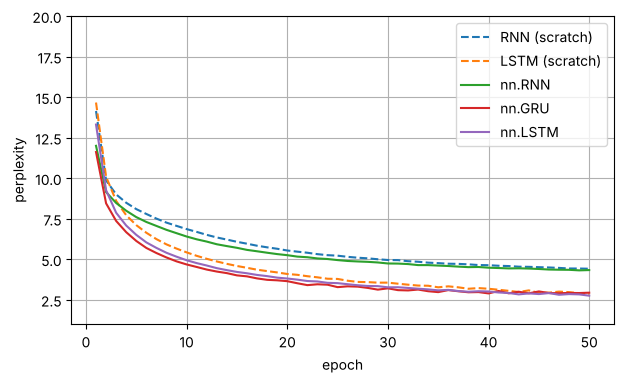

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, 51), ppl_rnn_scratch, '--', label='RNN (scratch)')
plt.plot(range(1, 51), ppl_lstm_scratch, '--', label='LSTM (scratch)')
for name, (_, ppl) in results.items():
    plt.plot(range(1, len(ppl) + 1), ppl, label=f'nn.{name}')
plt.xlabel('epoch')
plt.ylabel('perplexity')
plt.ylim(1, 20)
plt.legend()
plt.grid(True)
plt.show()

Final perplexities and a longer sample from each concise model:

In [13]:
for name, (model, ppl) in results.items():
    print(f'nn.{name:4s} perplexity {ppl[-1]:.2f}')
    print('   ', predict('the time traveller ', 120, model), '\n')

nn.RNN  perplexity 4.33
    the time traveller still the darkness of the darkness of the darkness of the darkness of the darkness of the darkness of the darkness of th 
nn.GRU  perplexity 2.94
    the time traveller and the thing the time traveller and the thing the time traveller and the thing the time traveller and the thing the tim 
nn.LSTM perplexity 2.75


    the time traveller s from the black of the side of a moment i had a most stared in the earth or space with a stare of the sun belt save for 


**Observations**
- All models go far below the uniform-guess perplexity of 28 (final: RNN ≈ 4.3, GRU ≈ 2.9, LSTM ≈ 2.75), and produce mostly real English words.
- Gated models (GRU / LSTM) reach lower perplexity than the vanilla RNN and can use larger learning rates.
- The fused `torch.nn` layers are faster than our Python loop over time steps (about 3× for the LSTM in this run).
- Greedy decoding tends to loop on frequent phrases ("the time traveller ..."); sampling from the softmax would give more varied text.

## Exercises

1. Replace greedy decoding with sampling: `torch.multinomial(F.softmax(Y[0, -1] / T, dim=0), 1)` for temperatures `T = 0.5, 1, 2`.
2. Remove gradient clipping from the vanilla RNN. What happens to training?
3. Stack two layers with `nn.LSTM(..., num_layers=2)`. Does perplexity improve?
4. Implement the GRU from scratch, following the LSTM class above.